# Chapter 11 · Project: distilling the twin into a fast network
2D · first run about 1 h (teacher + 7 trainings), then cached · *Rain twin, part 5*

Chapter 10's twin is slow: every 5 minutes it advects 40 ensemble members, runs a Kalman update
with about 770 observations, and needs the radar. As a *teacher* it has a lot going for it. It runs
over the whole summer, it is consistent in time, it fuses three sensors, and it gives a spread.

**Knowledge distillation** trains a small network, the *student*, to reproduce a teacher's
output from cheaper inputs. Here:

| | teacher | student |
|---|---|---|
| inputs | links, stations **and radar**, through time | link and station maps at t, t−5, t−10 min |
| method | ensemble Kalman filter with motion (`raintwin.system`) | 2-level U-Net, 216k weights (`raintwin.distill`) |
| output | now map and spread | the same two maps |
| cost per map | ~0.15 s on this laptop, and a radar feed | ~2 ms |

The radar is **privileged information**: the teacher uses it during training; the student never
sees it. A student like this could run on a network that has links and stations but no good
radar.

**Which teacher?** The fair test is three students with identical inputs and architecture,
trained on three different targets:
1. the **radar** itself (the usual way to train a learned link map);
2. FieldSense's static merge **RCP** (radar adjusted by links and stations);
3. the **twin**'s now map and spread.

**Rules.** Students train on the training weeks, are picked by the validation weeks, and are
scored on the 10 test storms of Chapter 10, at the 10 city gauges that no teacher and no student
ever saw.

In [1]:
import sys, time, pickle; sys.path.insert(0, "..")
from pathlib import Path
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from dtwin import viz
from raintwin import system, distill
from raintwin.cube import Cube
viz.set_style()
torch.set_num_threads(6)

CACHE = Path("../cache"); CACHE.mkdir(exist_ok=True)
c = Cube("openmrg")
GI = np.round(c.gauges["y"] / c.dx).astype(int), np.round(c.gauges["x"] / c.dx).astype(int)
ext = (-1, c.x[-1] + 1, -1, c.y[-1] + 1)

## 1. The teacher's lessons
The teacher runs over every wet period of the training and validation weeks (domain-mean link
rain above 0.03 mm/h, padded by an hour). This is the slow part, so it is cached
(`tools/teacher_labels.py` makes the same file).

In [2]:
f = CACHE / "teacher_openmrg.npz"
if not f.exists():
    wins = system.wet_windows(c)
    parts = [system.run(c, w, "LPR") for w in wins]
    np.savez_compressed(f, idx=np.concatenate(wins),
                        now=np.concatenate([p["now"] for p in parts]).astype("float16"),
                        spread=np.concatenate([p["spread"] for p in parts]).astype("float16"),
                        window=np.concatenate([np.full(len(w), j) for j, w in enumerate(wins)]), sensors="LPR")
T = np.load(f)
idx = T["idx"]
tr, va = c.split[idx] == 0, c.split[idx] == 1
print(f"teacher ({T['sensors']}): {len(idx)} wet steps, {len(np.unique(T['window']))} periods; "
      f"train {tr.sum()} steps, validation {va.sum()}")

teacher (LPR): 2437 wet steps, 29 periods; train 1571 steps, validation 866


## 2. Inputs and targets
Inputs: the link map **C** (FieldSense's line IDW), the station map **P**, and where each one has
data (**Ci**, **Pi**), at three times: 12 channels. Rain maps go in as log(1 + R).
Targets, also log(1 + R): the radar, RCP, or the twin's now map plus its spread. The radar and
RCP losses skip cells where the radar is missing.

inputs (2437, 12, 44, 35)   targets {'radar': (2437, 1, 44, 35), 'RCP': (2437, 1, 44, 35), 'twin': (2437, 2, 44, 35)}


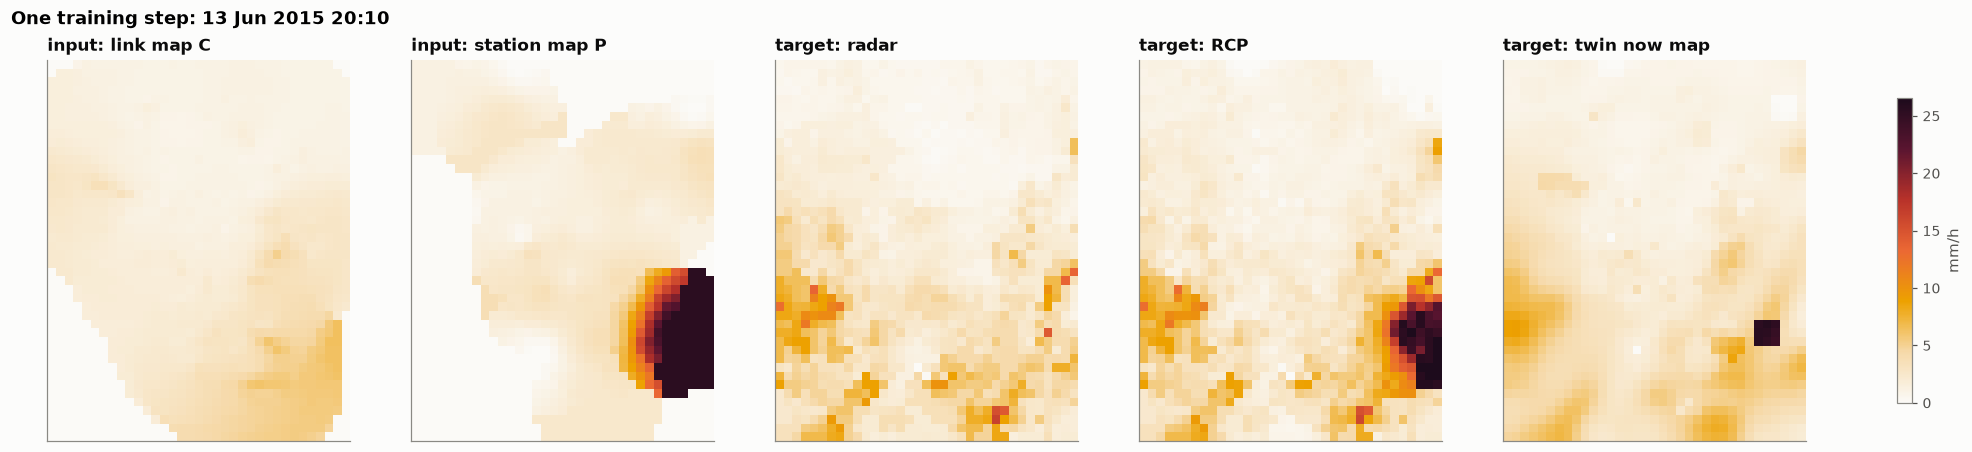

In [3]:
X = distill.stack_inputs(c, idx)
targets = {
    "radar": np.log1p(np.nan_to_num(c.radar(idx)))[:, None].astype("float32"),
    "RCP": np.log1p(np.nan_to_num(c.product("RCP", idx)))[:, None].astype("float32"),
    "twin": np.stack([np.log1p(T["now"].astype("float32")), np.log1p(T["spread"].astype("float32"))], 1),
}
valid = np.isfinite(c.radar(idx))[:, None].astype("float32")
print("inputs", X.shape, "  targets", {k: v.shape for k, v in targets.items()})

k_show = int(np.argmax(np.nanmean(T["now"].astype("float32"), (1, 2))))
fig, axes = plt.subplots(1, 5, figsize=(18, 4), constrained_layout=True)
show = [(np.expm1(X[k_show, 0]), "input: link map C"), (np.expm1(X[k_show, 2]), "input: station map P"),
        (np.expm1(targets["radar"][k_show, 0]), "target: radar"), (np.expm1(targets["RCP"][k_show, 0]), "target: RCP"),
        (np.expm1(targets["twin"][k_show, 0]), "target: twin now map")]
vm = np.percentile(np.expm1(targets["RCP"][k_show, 0]), 99.5)
for ax, (F, ttl) in zip(axes, show):
    ax.grid(False)
    im = ax.imshow(F, origin="lower", cmap=viz.FIELD, vmin=0, vmax=vm, extent=ext)
    ax.set(title=ttl, xticks=[], yticks=[])
plt.colorbar(im, ax=axes, shrink=0.8, label="mm/h")
fig.suptitle(f"One training step: {c.times[idx[k_show]]:%d %b %Y %H:%M}", x=0.01, ha="left", fontweight="bold")
viz.save(fig, "11_inputs_targets.png")
plt.show()

## 3. Training
Same network, same inputs, same 25 epochs (AdamW, cosine learning rate), best validation epoch
kept. The twin and RCP students are trained with three seeds each, so that a difference between
them can be told from training noise.

215,938 weights per student
best validation loss, radar target (seed 0): 0.0569
best validation loss, RCP target (seed 0): 0.0379
best validation loss, twin target (seed 0): 0.0140


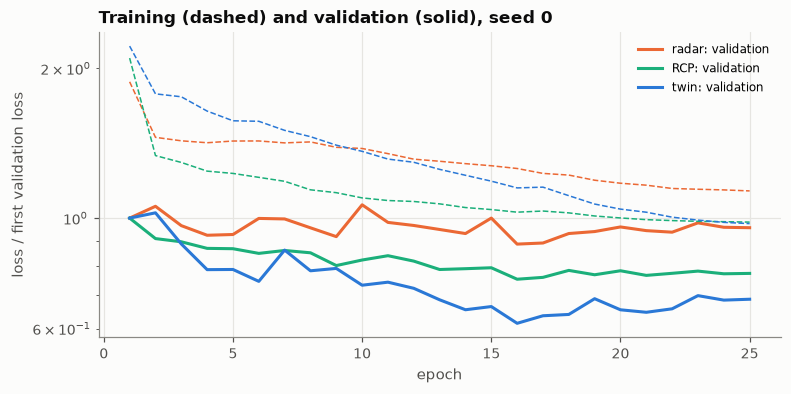

In [4]:
SEEDS = {"radar": [0], "RCP": [0, 1, 2], "twin": [0, 1, 2]}
COLOR = {"radar": viz.ORANGE, "RCP": viz.AQUA, "twin": viz.TWIN}       # one colour per teacher
nets, hist = {}, {}
for name, seeds in SEEDS.items():
    Y = targets[name]
    M = None if name == "twin" else valid
    for s in seeds:
        fw = CACHE / f"ch11_{name}_s{s}.pt"
        net = distill.Student(X.shape[1], Y.shape[1])
        if fw.exists():
            saved = torch.load(fw, weights_only=False)
            net.load_state_dict(saved["state"]); net.history = saved["history"]
        else:
            t0 = time.time()
            net = distill.train(X[tr], Y[tr], None if M is None else M[tr], X[va], Y[va],
                                None if M is None else M[va], epochs=25, seed=s, log=lambda m: None)
            torch.save({"state": net.state_dict(), "history": net.history}, fw)
            print(f"{name} seed {s}: {time.time() - t0:.0f}s")
        nets[(name, s)] = net
print(f"{sum(p.numel() for p in net.parameters()):,} weights per student")
for name in SEEDS:
    print(f"best validation loss, {name} target (seed 0): {np.nanmin(nets[(name, 0)].history[:, 1]):.4f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
for name in SEEDS:
    h = nets[(name, 0)].history
    ax.plot(np.arange(1, len(h) + 1), h[:, 1] / h[0, 1], color=COLOR[name], label=f"{name}: validation")
    ax.plot(np.arange(1, len(h) + 1), h[:, 0] / h[0, 1], color=COLOR[name], ls="--", lw=1)
ax.set(xlabel="epoch", ylabel="loss / first validation loss", yscale="log",
       title="Training (dashed) and validation (solid), seed 0")
ax.legend(fontsize=8)
plt.show()

The twin is the easiest teacher to imitate: its best validation loss is several times lower than
for the other two. It is smooth and consistent from one step to the next, so most of it can be
predicted from links and stations. The radar is the hardest: much of what it shows (its own noise,
its bias against the links) cannot be predicted from the links.

## 4. The exam: 10 storms, 10 gauges

In [5]:
SPIN = 12
steps = [c.index(s - pd.Timedelta("1h"), e)[SPIN:] for _, s, e in c.events()]
ti = np.concatenate(steps)
Xt = distill.stack_inputs(c, ti)
G = c.gauge_rain(ti)
HOURS = c.times[ti].ceil("h")


def hourly(a):
    return pd.DataFrame(a / 12, index=HOURS).groupby(level=0).sum(min_count=12).values


GH = hourly(G)


def score(E):
    Eh = hourly(E)
    ok, ok5 = np.isfinite(Eh) & np.isfinite(GH), np.isfinite(E) & np.isfinite(G)
    return dict(nrmse=np.sqrt(np.mean((Eh[ok] - GH[ok]) ** 2)) / GH[ok].mean(),
                corr=np.corrcoef(Eh[ok], GH[ok])[0, 1], bias=Eh[ok].mean() / GH[ok].mean() - 1,
                corr5=np.corrcoef(E[ok5], G[ok5])[0, 1])


rows, outs, timing = {}, {}, {}
for p, lab in [("CP", "static: links + stations IDW (same inputs)"), ("R", "static: radar"),
               ("RCP", "static: RCP, uses radar")]:
    rows[lab] = score(c.product(p, ti)[:, GI[0], GI[1]])
for (name, s), net in nets.items():
    t0 = time.time()
    out = distill.predict(net, Xt)
    timing[name] = (time.time() - t0) / len(Xt)
    outs[(name, s)] = out
    rows[f"student <- {name}, seed {s}"] = score(out[:, 0][:, GI[0], GI[1]])
R = pd.DataFrame(rows).T
print(R.round(3).to_string())
for name in SEEDS:
    v = R.loc[[f"student <- {name}, seed {s}" for s in SEEDS[name]], "nrmse"]
    print(f"student <- {name}: NRMSE {v.mean():.3f} (seeds {v.min():.3f} to {v.max():.3f})")
print(f"student: {np.mean(list(timing.values())) * 1e3:.1f} ms per map on this CPU")

                                            nrmse   corr   bias  corr5
static: links + stations IDW (same inputs)  1.064  0.842  0.046  0.722
static: radar                               1.471  0.712 -0.021  0.401
static: RCP, uses radar                     0.994  0.868  0.057  0.723
student <- radar, seed 0                    1.634  0.732 -0.479  0.549
student <- RCP, seed 0                      1.040  0.850 -0.030  0.709
student <- RCP, seed 1                      1.047  0.852  0.052  0.706
student <- RCP, seed 2                      1.003  0.861 -0.018  0.724
student <- twin, seed 0                     1.026  0.857 -0.014  0.702
student <- twin, seed 1                     1.034  0.852 -0.019  0.700
student <- twin, seed 2                     1.003  0.861 -0.037  0.711
student <- radar: NRMSE 1.634 (seeds 1.634 to 1.634)
student <- RCP: NRMSE 1.030 (seeds 1.003 to 1.047)
student <- twin: NRMSE 1.021 (seeds 1.003 to 1.034)
student: 8.6 ms per map on this CPU


the teacher itself on the test storms (Chapter 10, twin LPR now map): NRMSE 1.062


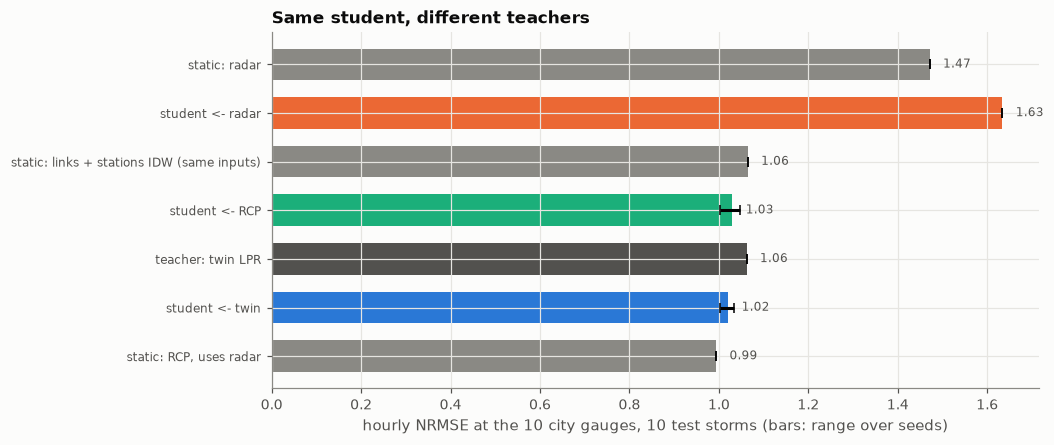

In [6]:
if (CACHE / "ch10_runs.pkl").exists():
    ch10 = pickle.load(open(CACHE / "ch10_runs.pkl", "rb"))
    teacher_score = score(ch10["LPR"]["now"])["nrmse"]
    print(f"the teacher itself on the test storms (Chapter 10, twin LPR now map): NRMSE {teacher_score:.3f}")
else:
    teacher_score = np.nan

labels = ["static: radar", "student <- radar", "static: links + stations IDW (same inputs)",
          "student <- RCP", "teacher: twin LPR", "student <- twin", "static: RCP, uses radar"]
vals, errs = [], []
for lab in labels:
    if lab.startswith("student"):
        name = lab.split("<- ")[1]
        v = R.loc[[f"student <- {name}, seed {s}" for s in SEEDS[name]], "nrmse"]
        vals.append(v.mean()); errs.append([v.mean() - v.min(), v.max() - v.mean()])
    elif lab.startswith("teacher"):
        vals.append(teacher_score); errs.append([0, 0])
    else:
        vals.append(R.loc[lab, "nrmse"]); errs.append([0, 0])
fig, ax = plt.subplots(figsize=(9, 4.2))
cols = [viz.MUTED, COLOR["radar"], viz.MUTED, COLOR["RCP"], viz.INK2, COLOR["twin"], viz.MUTED]
ax.barh(range(len(labels)), vals, xerr=np.array(errs).T, color=cols, height=0.65, capsize=3)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
ax.invert_yaxis()
for i, v in enumerate(vals):
    ax.text(v + 0.03, i, f"{v:.2f}", va="center", fontsize=8, color=viz.INK2)
ax.set(xlabel="hourly NRMSE at the 10 city gauges, 10 test storms (bars: range over seeds)",
       title="Same student, different teachers")
viz.save(fig, "11_scores.png")
plt.show()

**Reading the exam.**
* **Trained on the radar, the student is bad** (1.63, half the rain missing). It learns the
  radar's level and the radar's misses. A learned link map is only as good as the map it is
  trained on.
* **Trained on the twin, the student scores 1.02** over three seeds (1.00 to 1.03). That is
  better than IDW of the same inputs (1.06) and better than **its own teacher** (1.06). The
  student cannot copy the teacher's step-to-step noise, only what is predictable from links and
  stations, and that part turns out to be the better map at the gauges.
* **Trained on RCP, the student is about as good on its best seed (1.00) and a little less
  steady**: 1.00 to 1.05 over the seeds. RCP is rebuilt from scratch every 5 minutes and jumps
  where the radar jumps; the twin's targets change smoothly. The average gap between the two
  teachers (1.02 against 1.03) is small, and three seeds are not many, so read it as "at least
  as good and a little steadier", not as a clear win.
* The best static map, RCP, still wins (0.99). But it needs the radar at run time; the student
  does not.

## 5. Maps

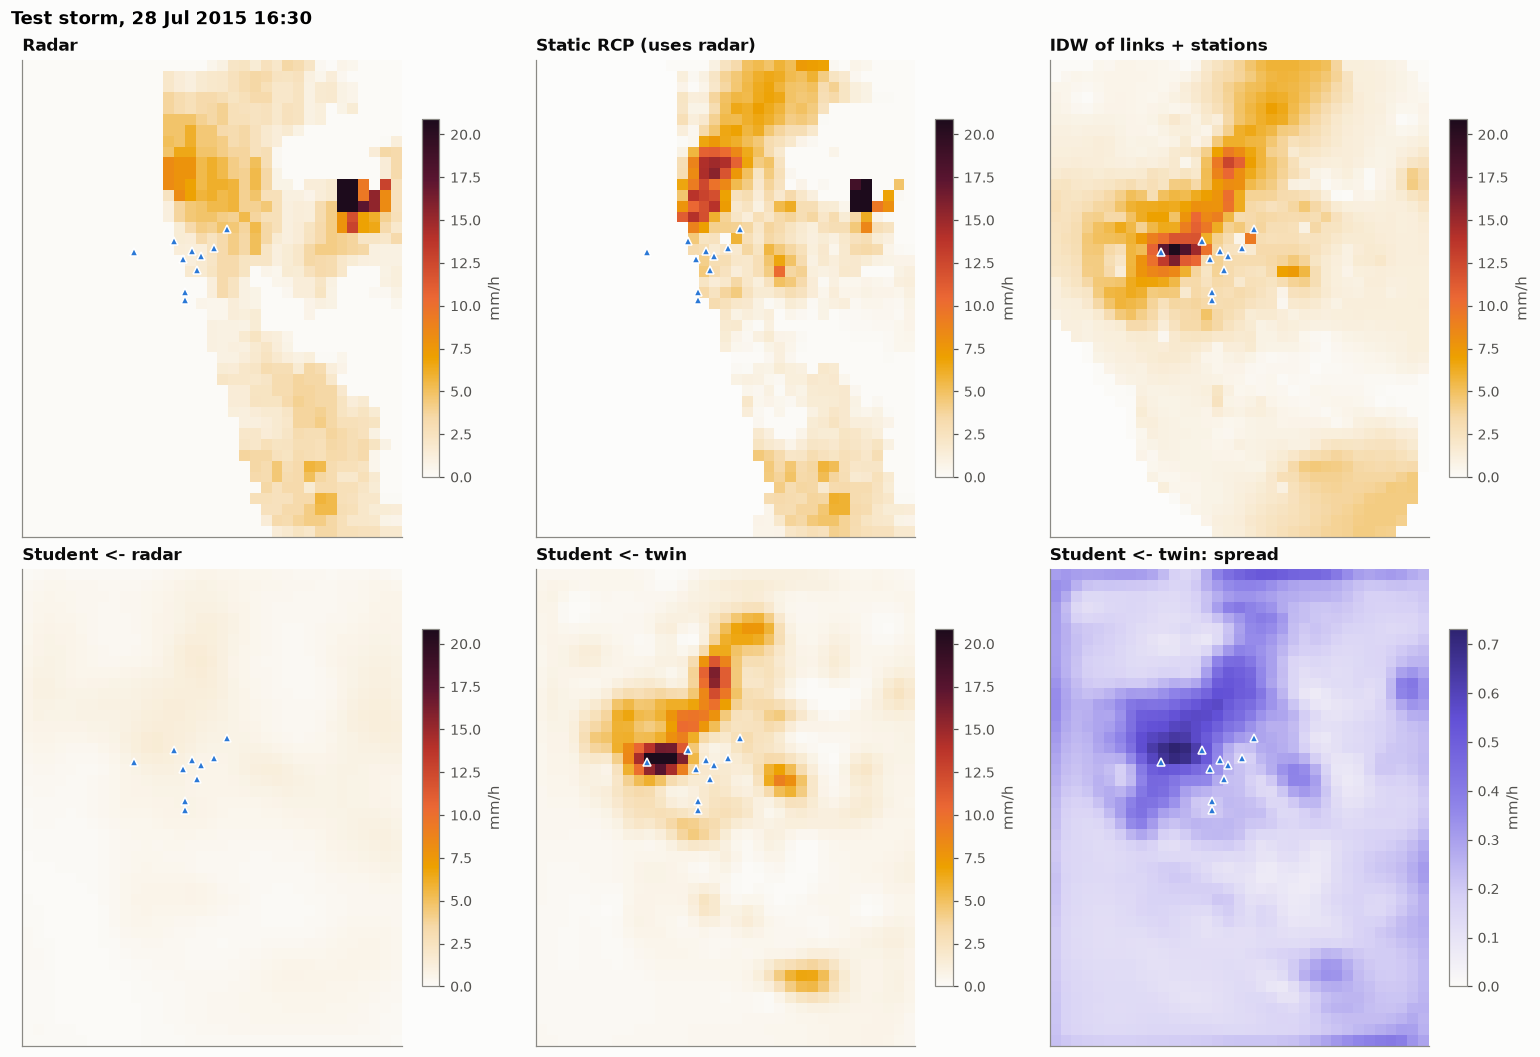

In [7]:
st = steps[[i for i, (n, _, _) in enumerate(c.events()) if n == "20150728T03"][0]]
k = int(np.nanargmax(np.nanmean(c.radar(st), (1, 2))))
j = int(np.flatnonzero(ti == st[k])[0])
panels = [(np.nan_to_num(c.radar(st[[k]])[0]), "Radar", viz.FIELD),
          (c.product("RCP", st[[k]])[0], "Static RCP (uses radar)", viz.FIELD),
          (c.product("CP", st[[k]])[0], "IDW of links + stations", viz.FIELD),
          (outs[("radar", 0)][j, 0], "Student <- radar", viz.FIELD),
          (outs[("twin", 0)][j, 0], "Student <- twin", viz.FIELD),
          (outs[("twin", 0)][j, 1], "Student <- twin: spread", viz.UNCERTAINTY)]
vm = np.nanpercentile(panels[1][0], 99.5)
fig, axes = plt.subplots(2, 3, figsize=(14, 9.5), constrained_layout=True)
for ax, (F, ttl, cm) in zip(axes.ravel(), panels):
    ax.grid(False)
    im = ax.imshow(F, origin="lower", cmap=cm, vmin=0, vmax=vm if cm is viz.FIELD else None, extent=ext)
    ax.plot(c.gauges["x"], c.gauges["y"], "^", color=viz.BLUE, ms=5, mec="white")
    ax.set(title=ttl, xticks=[], yticks=[])
    plt.colorbar(im, ax=ax, shrink=0.75, label="mm/h")
fig.suptitle(f"Test storm, {c.times[st[k]]:%d %b %Y %H:%M}", x=0.01, ha="left", fontweight="bold")
viz.save(fig, "11_maps.png")
plt.show()

## 6. Is the learned spread honest?
The twin student also predicts the teacher's spread. If the spread were a calibrated standard
deviation, a gauge reading would fall within mean ± k·spread for the share of a normal
distribution: 68 % at k = 1, 95 % at k = 2.

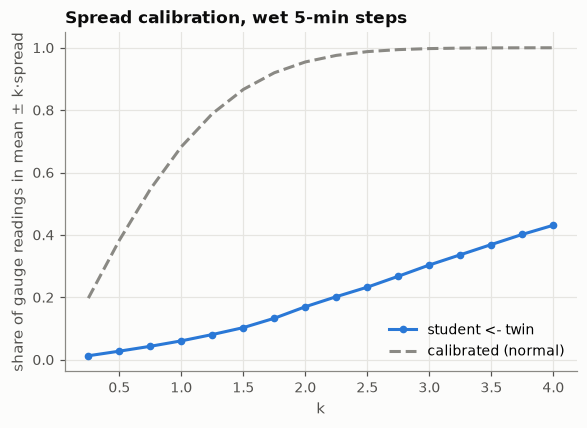

k = 1: 6% (calibrated: 68%)
k = 2: 17% (calibrated: 95%)
the spread would need to be 12.7 times larger for 95 % at k = 2


In [8]:
m = outs[("twin", 0)][:, 0][:, GI[0], GI[1]]
s = outs[("twin", 0)][:, 1][:, GI[0], GI[1]]
ok = np.isfinite(G) & (np.maximum(G, m) > 0.1)
ks = np.linspace(0.25, 4, 16)
cover = [np.mean(np.abs(G[ok] - m[ok]) <= kk * s[ok]) for kk in ks]
from scipy.stats import norm
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ks, cover, "o-", color=viz.TWIN, ms=4, label="student <- twin")
ax.plot(ks, 2 * norm.cdf(ks) - 1, "--", color=viz.MUTED, label="calibrated (normal)")
ax.set(xlabel="k", ylabel="share of gauge readings in mean ± k·spread",
       title="Spread calibration, wet 5-min steps")
ax.legend()
plt.show()
for kk in (1, 2):
    print(f"k = {kk}: {np.mean(np.abs(G[ok] - m[ok]) <= kk * s[ok]):.0%} (calibrated: {2 * norm.cdf(kk) - 1:.0%})")
scale = np.quantile(np.abs(G[ok] - m[ok]) / np.maximum(s[ok], 1e-3), 0.95) / 2
print(f"the spread would need to be {scale:.1f} times larger for 95 % at k = 2")

The learned spread is far too narrow, like the teacher's (Chapter 10): it would need to be more
than ten times larger. A single scale factor fitted on the validation weeks is the standard
fix, but an error that large says the teacher's spread describes the ensemble, not the gap
between a 2 km map and a gauge. Before the spread is quoted as an error bar, the teacher's
noise model has to include that sub-cell variability.

## Conclusions
* A twin is a good teacher. Distilled into a 2 ms network that sees only links and stations, it
  gives a better map at independent gauges than IDW of the same data and than a student trained
  on the radar, and a slightly steadier one than a student trained on the static merge.
* The student beat its own teacher at the gauges (1.02 against 1.06): it keeps what is
  predictable and drops the teacher's noise.
* Training a link map on radar copies the radar's errors. On a network whose radar is weak, the
  target matters more than the architecture.
* The spread can be distilled too, but it inherits the teacher's over-confidence, by a factor
  of about ten.

**Next.** Recalibrate the spread on validation weeks; add the twin's forecast as a second target
so the student also nowcasts; and try the same teacher-student pair in New York (Chapter 12),
where the radar is better and the links are fewer.